Romain Amigon, Conrad Seidel FISE2

# Consignes

A partir de ce notebook de base, l'objectif de ce projet est d'entrainer un VAE sur le jeu de données [CelebA](http://mmlab.ie.cuhk.edu.hk/projects/CelebA.html), disponible sur [torchvision](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.CelebA.html) ou un sous ensemble de ce jeu de données (il est un peu gros).

Trois objectifs, à réaliser séquentiellement:

- Partie 1 : Entrainer le modèle avec flatten puis MLP (sur 7)
- Partie 2 : Utiliser des CNN à la place de MLP (vous pouvez vous inspirer de l'[implementation suivante](https://medium.com/the-generator/a-basic-variational-autoencoder-in-pytorch-trained-on-the-celeba-dataset-f29c75316b26) (sur 3)
- Partie 3 : Trouver un moyen de conditionner le VAE avec les attributs des images (lunette, moustache etc), l'entrainer et générer votre tête avec des lunettes (sur 6)

La présentation et la qualité des résultats sera noté sur 4.

Rendu : 30 Mai à 12h sur Mootse


## Sommaire

- [Initialisation](#INITIALISAION)
- [PARTIE 1 :VAE ](#PARTIE-1)
- [PARTIE II : CNN](#PARTIE-II)
- [PARTIE III : features](#PARTIE-III)
- [AMELIORATION](#AMELIORATION)


# Initialisation

## Imports et paramètres initiaux

Dans cette section, nous allons :
1. Importer les bibliothèques nécessaires (PyTorch, matplotlib, numpy)
2. Configurer le device (GPU/CPU)
3. Définir la liste des attributs CelebA

Ces attributs seront utilisés plus tard pour le conditionnement du VAE dans la partie 3.

***

# Imports et configuration

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt
import numpy as np

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Using {device} device")
if device==torch.device("cuda"):print(torch.cuda.get_device_name(0))  # Nom du GPU


features=np.array(["5_o_Clock_Shadow","Arched_Eyebrows","Attractive",
          "Bags_Under_Eyes","Bald","Bangs","Big_Lips","Big_Nose",
          "Black_Hair","Blond_Hair","Blurry","Brown_Hair","Bushy_Eyebrows",
          "Chubby","Double_Chin","Eyeglasses","Goatee","Gray_Hair","Heavy_Makeup",
          "High_Cheekbones","Male","Mouth_Slightly_Open","Mustache","Narrow_Eyes",
          "No_Beard","Oval_Face","Pale_Skin","Pointy_Nose","Receding_Hairline","Rosy_Cheeks",
          "Sideburns","Smiling","Straight_Hair","Wavy_Hair","Wearing_Earrings","Wearing_Hat","Wearing_Lipstick",
          "Wearing_Necklace","Wearing_Necktie","Young"])

Using cuda device
Tesla T4


***

# Préparation des données

## Téléchargement du Dataset CelebA depuis Kaggle

Le jeu de données CelebA contient plus de 200 000 images de visages de célébrités, chacune annotée avec 40 attributs binaires. La préparation des données comprend :

1. Configuration de l'accès à l'API Kaggle
2. Téléchargement du dataset (environ 1.3 GB)
3. Extraction des fichiers dans le dossier data/celeba



On a décidé d'utiliser un dataset miroir de Celeba (jessicali9530/celeba-dataset) car google drive bloque très souvent l'importation du dataset officiel


In [ ]:
# Étape 1 : autoriser l'accès à l'API Kaggle
!mkdir -p ~/.kaggle
from google.colab import files
uploaded = files.upload()  # Importez ici votre kaggle.json téléchargé depuis https://www.kaggle.com/account

# Étape 2 : déplacer le fichier kaggle.json
import shutil
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
!chmod 600 /root/.kaggle/kaggle.json

# Étape 3 : télécharger le dataset CelebA (≈1.3 GB)
!kaggle datasets download -d jessicali9530/celeba-dataset
!mkdir -p data

# Étape 4 : extraire les fichiers
!unzip -q celeba-dataset.zip -d data/celeba


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
celeba-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/celeba/img_align_celeba/img_align_celeba/000001.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: no all
replace data/celeba/img_align_celeba/img_align_celeba/000002.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: all
error:  invalid response [all]
replace data/celeba/img_align_celeba/img_align_celeba/000002.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace data/celeba/img_align_celeba/img_align_celeba/000003.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/celeba/img_align_celeba/img_align_celeba/000004.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/celeba/img_align_celeba/img_align_celeba/000005.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/celeba/img_align_celeba/img_align_celeba/000006.jpg? [y]es, [n]o, [A]ll, [N]one, [r]

Vérification

In [ ]:
import os

celeba_path = '/content/data/celeba/img_align_celeba/img_align_celeba'
print(os.getcwd())
files = os.listdir(celeba_path)
print(f"Nombre de fichiers : {len(files)}")
print("Exemples de fichiers :", files[:10])

/content
Nombre de fichiers : 202599
Exemples de fichiers : ['098095.jpg', '126988.jpg', '014768.jpg', '081061.jpg', '053234.jpg', '094842.jpg', '026291.jpg', '137790.jpg', '077012.jpg', '160481.jpg']


***
# Préparation des données personnalisée

Nous devons générer le dataset torch à partir des données de kaggle

In [ ]:
import pandas as pd
from torch.utils.data import Dataset
from torchvision.transforms import Compose, Resize
from torchvision.io import read_image

celeba_root = "/content/data/celeba"
img_dir = os.path.join(celeba_root, "img_align_celeba/img_align_celeba")
attr_path = os.path.join(celeba_root, "list_attr_celeba.csv")
partition_path = os.path.join(celeba_root, "list_eval_partition.csv")

attr_df = pd.read_csv(
    attr_path,
    skiprows=1,
    names=['filename'] + features.tolist(),
        index_col='filename'
)
#print(attr_df)

partition_df = pd.read_csv(
    partition_path,
    header=None,
    names=['filename', 'partition'],
    index_col='filename'
)

partition_df.columns = ['partition']
#print(partition_df)

attr_df['partition'] = partition_df['partition']
#print(attr_df)

class CustomCelebADataset(Dataset):
    def __init__(self, img_dir, attr_df, transform=None):
        self.img_dir = img_dir
        self.attr_df = attr_df
        self.transform = transform
        self.image_names = attr_df.index.tolist()

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        img_name = self.image_names[idx]
        img_path = os.path.join(self.img_dir, img_name)
        image = read_image(img_path).float() / 255.0
        label = torch.tensor(self.attr_df.loc[img_name].values, dtype=torch.float32)

        if self.transform:
            image = self.transform(image)

        return image, label

train_df = attr_df[attr_df['partition'] == "0"].drop(columns='partition')
test_df  = attr_df[attr_df['partition'] == "2"].drop(columns='partition')

training_data = CustomCelebADataset(img_dir, train_df)
test_data  = CustomCelebADataset(img_dir, test_df)

            5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
filename                                                                     
000001.jpg                -1                1           1               -1   
000002.jpg                -1               -1          -1                1   
000003.jpg                -1               -1          -1               -1   
000004.jpg                -1               -1           1               -1   
000005.jpg                -1                1           1               -1   
...                      ...              ...         ...              ...   
202595.jpg                -1               -1           1               -1   
202596.jpg                -1               -1          -1               -1   
202597.jpg                -1               -1          -1               -1   
202598.jpg                -1                1           1               -1   
202599.jpg                -1                1           1       

***

# Téléchargement depuis torchvision

Cette méthode n'a pas fonctionné pour nous, on rencontrait toujours une erreur au moment du téléchargement depuis le drive. Nous utilisons ici la classe `CelebA` de torchvision comme alternative au téléchargement depuis Kaggle. Cette méthode offre :

1. Un téléchargement automatisé
2. Une séparation train/test déjà effectuée
3. Des transformations intégrées (ToTensor, normalisation)

In [ ]:
# Download training data from open datasets.
training_data = datasets.CelebA(
    root="/content/data/", # Changed root to the actual extraction path
    split="train",
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.CelebA(
    root="/content/data/celeba", # Changed root to the actual extraction path
    split="test",
    download=False,
    transform=ToTensor(),
)

----------------
###Vérification

In [ ]:
print(training_data.__len__())
print(test_data.__len__())

162770
19962


['Arched_Eyebrows' 'Attractive' 'Brown_Hair' 'Heavy_Makeup'
 'High_Cheekbones' 'Mouth_Slightly_Open' 'No_Beard' 'Pointy_Nose'
 'Smiling' 'Straight_Hair' 'Wearing_Earrings' 'Wearing_Lipstick' 'Young']


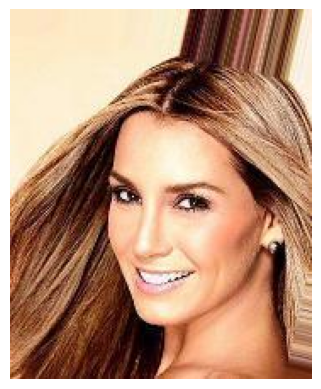

torch.Size([218, 178, 3])


In [ ]:
# Tests pour vérifier la bonne implémentation du dataset
img, attr = training_data[0]
img = img.permute(1, 2, 0)

attr = attr.numpy()

plt.imshow(img)
plt.axis('off')
print(features[attr == 1])
plt.show()
print(img.shape)

###Dataloader

In [ ]:
batch_size = 512

# Création des data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")

    break

Shape of X [N, C, H, W]: torch.Size([512, 3, 218, 178])
Shape of y: torch.Size([512, 40]) torch.float32


------------------------------------------------------------------------


# PARTIE I VAE

In [ ]:
#device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
#print(f"Using {device} device")

# Définition du modèle
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.encoder_mu = nn.Sequential(
            nn.Linear(3*218*178, 512),
            nn.ReLU(),
            #nn.Dropout(0.2),
            nn.Linear(512, 64),
            nn.ReLU(),
            #nn.Dropout(0.2),
            nn.Linear(64, 2)
        )

        self.encoder_logvar = nn.Sequential(
            nn.Linear(3*218*178, 512),
            nn.ReLU(),
            #nn.Dropout(0.2),
            nn.Linear(512, 256),
            nn.ReLU(),
            #nn.Dropout(0.2),
            nn.Linear(256, 2)
        )

        self.decoder = nn.Sequential(
            nn.Linear(2, 256),
            nn.ReLU(),
            #nn.Dropout(0.2),
            nn.Linear(256, 512),
            nn.ReLU(),
            #nn.Dropout(0.2),
            nn.Linear(512, 3*218*178),
            nn.Sigmoid()
        )


    def forward(self, x, train=True):
        x = self.flatten(x)
        z_mu = self.encoder_mu(x)
        z_logvar = self.encoder_logvar(x)
        std = torch.exp(0.5 * z_logvar)
        if train:
            epsilon = torch.randn_like(std)
            z = z_mu + std * epsilon
        else:
            z = z_mu
        x_hat = self.decoder(z)
        return x_hat, z_mu, z_logvar


model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (encoder_mu): Sequential(
    (0): Linear(in_features=116412, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
  (encoder_logvar): Sequential(
    (0): Linear(in_features=116412, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=116412, bias=True)
    (5): Sigmoid()
  )
)


***

## Entraînement du modèle

Nous utilisons :
- **MSE Loss** pour la perte de reconstruction
- **KL Divergence** pour régulariser la distribution latente
- **Optimiseur Adam** avec un learning rate de 1e-4

### Fonction d'entraînement
- Calcul de la perte totale (reconstruction + KL)
- Backpropagation et mise à jour des poids
- Suivi de la progression avec affichage régulier

In [ ]:
# Fonction de perte ELBO dans l'entraînement et optimiseur Adam
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, _) in enumerate(dataloader):
        X = X.to(device)

        # Compute prediction error
        pred,mu,log_sigma = model(X)
        reconstruction_loss = torch.sum((pred.reshape(X.shape[0],3,218,178) -  X).pow(2))
        kl = torch.sum(mu.pow(2) + log_sigma.exp() -1 - log_sigma)
        loss = reconstruction_loss + kl

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

***

## Évaluation du modèle

La fonction de test permet de :
1. Évaluer les performances sur le jeu de test
2. Vérifier la qualité de reconstruction
3. Calculer la perte moyenne sur l'ensemble de test

In [ ]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            pred,_,_ = model(X,train=False)
            test_loss += loss_fn(pred.reshape(X.shape[0],3,218,178), X).item()
    test_loss /= num_batches
    correct /= size
    print(f"Test loss: {test_loss:>8f} \n")

Nous avons mis un faible nombre d'epochs car notre matériel n'est pas assez performant pour entrainer assez rapidement

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2764447.750000  [  256/162770]
loss: 1715989.750000  [25856/162770]
loss: 1424478.375000  [51456/162770]
loss: 1395646.375000  [77056/162770]
loss: 1441090.750000  [102656/162770]
loss: 1451677.500000  [128256/162770]
loss: 1400487.500000  [153856/162770]
Test loss: 0.046864 

Epoch 2
-------------------------------
loss: 1440982.125000  [  256/162770]
loss: 1520821.375000  [25856/162770]
loss: 1336874.625000  [51456/162770]
loss: 1312870.375000  [77056/162770]
loss: 1386471.000000  [102656/162770]
loss: 1396459.250000  [128256/162770]
loss: 1369218.375000  [153856/162770]
Test loss: 0.045349 

Epoch 3
-------------------------------
loss: 1377971.875000  [  256/162770]
loss: 1453338.250000  [25856/162770]
loss: 1296363.750000  [51456/162770]
loss: 1281854.625000  [77056/162770]
loss: 1378923.875000  [102656/162770]
loss: 1372934.000000  [128256/162770]
loss: 1355774.500000  [153856/162770]
Test loss: 0.044678 

Epoch 4
--------------------




Temps d'entrainement : ~1h sur NVIDIA GeForce RTX 3060 Laptop GPU

Enregistrer le modèle

In [ ]:
import time

timestamp = time.strftime("%Y%m%d-%H%M%S")
filename = f"vae_model_{timestamp}.pth"
torch.save(model.state_dict(), filename)

Test sur le premier batch

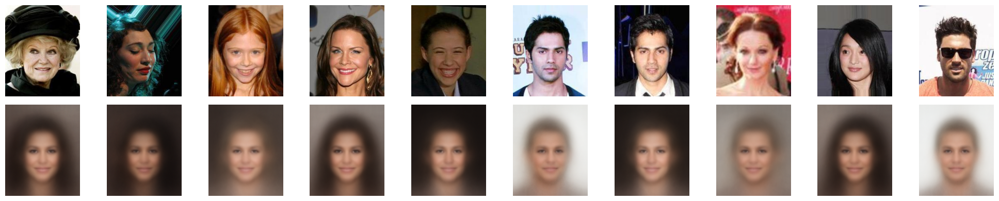

In [ ]:
import matplotlib.pyplot as plt

X, y = next(iter(test_dataloader))
X = X.to(device)
pred, _, _ = model(X, train=False)
pred = pred.reshape(X.shape[0],3,218,178)
def plot_images(originals, predictions, num_images=10):
    fig, axes = plt.subplots(2, num_images, figsize=(2 * num_images, 4))
    for i in range(num_images):
        axes[0, i].imshow(originals[i].permute(1, 2, 0).cpu().squeeze())
        axes[0, i].axis("off")
        axes[1, i].imshow(predictions[i].permute(1, 2, 0).detach().cpu().squeeze())
        axes[1, i].axis("off")
    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Reconstruit")
    plt.tight_layout()
    plt.show()

plot_images(X, pred, num_images=10)

***

## Visualisation des résultats

### Comparaison des reconstructions

Nous comparons :
- Les images originales (ligne supérieure)
- Les reconstructions par le VAE (ligne inférieure)

Cela permet d'évaluer visuellement la qualité de reconstruction et la capacité du modèle à capturer les caractéristiques importantes des visages.

In [ ]:
def test_encode(dataloader, model, attribute_idx=0):
    model.eval()
    all_latents = []
    labels = []

    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            _, mu, _ = model(X, train=False)
            all_latents.append(mu.cpu().numpy())

            y_np = y.cpu().numpy()
            labels.extend(y_np[:, attribute_idx].tolist())
    z = np.vstack(all_latents)
    print("Exemple de labels:", labels[:10])
    return z, labels

***

## Analyse de l'espace latent

L'objectif est d'explorer l'organisation de l'espace latent en :
1. Encodant des images du jeu de test
2. Visualisant la distribution des points dans l'espace latent
3. Analysant la relation avec les attributs

Cette analyse nous permet de comprendre comment le modèle organise l'information.

Exemple de labels: [0, 0, 0, 0, 0, 1, 1, 0, 0, 1]
(19962, 2)


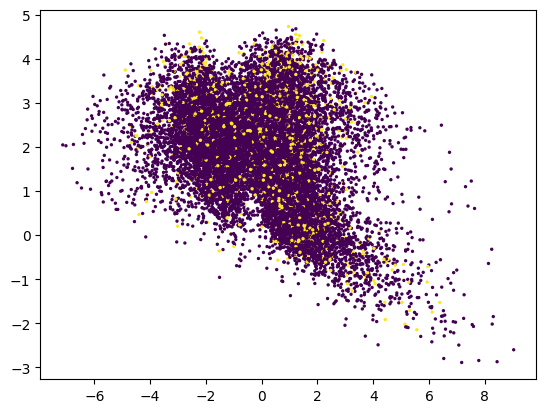

In [ ]:
Z,ys = test_encode(test_dataloader, model)
print(Z.shape)
plt.scatter(Z[:,0], Z[:,1],c = ys,s = 2)

On remarque qu'il n'ya pas de distribution particulière des attributs dans l'espace latent. Pour vérifier que le réseau a bien appris, on va tenter de générer aléatoirement une image et vérifier que le réseau reconstruit une forme de visage.

***

## Génération d'images aléatoirement

### Processus de génération
1. Échantillonnage de points dans l'espace latent
2. Décodage vers l'espace des images
3. Visualisation des résultats

Cette expérience permet de vérifier que le modèle a bien appris une représentation cohérente des visages.

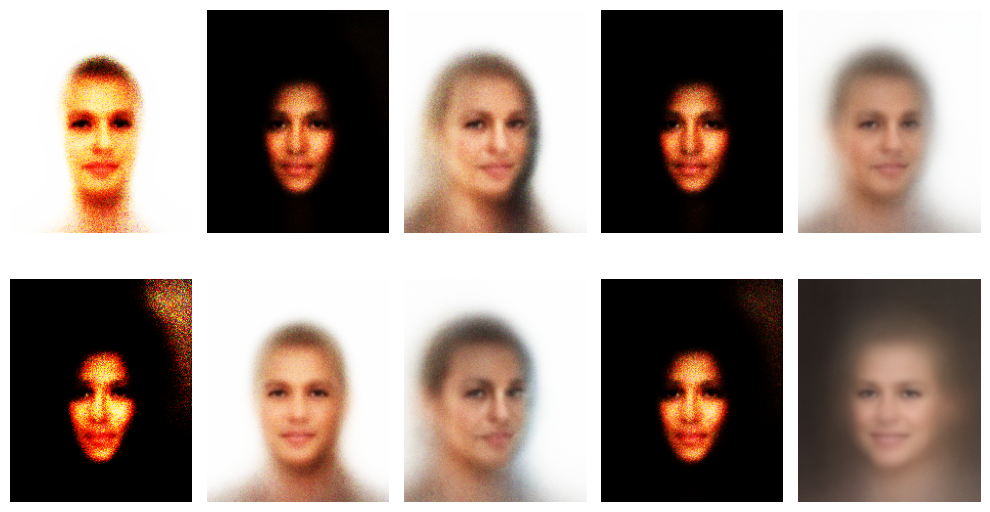

In [ ]:
import matplotlib.pyplot as plt
import torch


fig, axes = plt.subplots(2, 5, figsize=(10, 6))

axes = axes.flatten()

for i in range(10):
    code = 10 * torch.randn(2).to(device)
    y = model.decoder(code)
    image = y.cpu().detach().numpy().reshape(3,218, 178)
    axes[i].imshow(np.transpose(image, (1, 2, 0))  , cmap="gray")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

On remarque que les résultats donnent une forme cohérente de visage. Le réseau a donc bien appris.

***

# PARTIE II : VAE Convolutif

## Amélioration de l'architecture avec CNN

Dans cette partie, nous améliorons le VAE en utilisant des réseaux de neurones convolutifs (CNN), on s'est inspiré de la ressource donnée au début, pour :

1. Mieux capturer la structure spatiale des images
2. Réduire le nombre de paramètres
3. Améliorer la qualité des reconstructions

### Architecture proposée
- Encodeur : Couches Conv2D avec BatchNorm
- Décodeur : Couches ConvTranspose2D symétriques
- Dimension latente augmentée à 20

Nous avons mis une dimension latente de 20 afin d'avoir un compromis entre la perte de données et l'efficacité. Une dimension de 20 permet d'appliquer un algorithme de réduction de dimensionnalité simple, comme le PCA, sans perdre trop d'information ou un algorithme plus complexe, comme Umap, plus rapidement.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Déclaration du modèle CNN pour l'autoencodeur variationnel (VAE)
class CNN(nn.Module):

    def __init__(self, latent_dim=20):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.Conv2d(32, 64,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.Conv2d(64, 128,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.Conv2d(128, 256,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.Conv2d(256,512,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU()
        )

        input_shape = (3, 218, 178)
        _, h, w = input_shape
        for _ in range(5):
            h = (h + 2*1 - 1*(3 - 1) - 1)//2 + 1
            w = (w + 2*1 - 1*(3 - 1) - 1)//2 + 1
        self.h = h
        self.w = w

        self.flatten_dim = 512 * h * w

        self.fc_mu = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_dim, latent_dim)

        self.fc_dec = nn.Linear(latent_dim, self.flatten_dim)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 256, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(256, 128,kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(128, 64,kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.Sigmoid()
        )

    def encode(self, x):
        y = self.encoder(x)
        y = y.view(y.size(0), -1)  # important
        mu = self.fc_mu(y)
        logvar = self.fc_logvar(y)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_dec(z)
        h = h.view(h.size(0), 512, self.h, self.w)
        out = self.decoder(h)
        return out

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        x_hat = x_hat[:, :, :x.size(2), :x.size(3)]

        return x_hat, mu, logvar

model = CNN().to(device)
print(model)


CNN(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.01)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.01)
    (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track

In [ ]:
# On garde la même fonction de êrte et le même optimiseur
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, _) in enumerate(dataloader):
        X = X.to(device)

        # Compute prediction error
        pred,mu,log_sigma = model(X)
        reconstruction_loss = torch.sum((pred -  X).pow(2))
        kl = torch.sum(mu.pow(2) + log_sigma.exp() -1 - log_sigma)
        loss = reconstruction_loss + kl

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

In [ ]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            pred,_,_ = model(X)
            test_loss += loss_fn(pred, X).item()
    test_loss /= num_batches
    correct /= size
    print(f"Test loss: {test_loss:>8f} \n")

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

print("Done!")

Epoch 1
-------------------------------
loss: 6886112.000000  [  512/162770]
loss: 3862516.750000  [51712/162770]
loss: 2295811.000000  [102912/162770]
loss: 1748656.250000  [154112/162770]
Test loss: 0.027151 

Epoch 2
-------------------------------
loss: 1714755.875000  [  512/162770]
loss: 1433676.250000  [51712/162770]
loss: 1350367.500000  [102912/162770]
loss: 1280977.500000  [154112/162770]
Test loss: 0.020639 

Epoch 3
-------------------------------
loss: 1316345.250000  [  512/162770]
loss: 1230740.375000  [51712/162770]
loss: 1230507.625000  [102912/162770]
loss: 1195647.375000  [154112/162770]
Test loss: 0.019403 

Epoch 4
-------------------------------
loss: 1237399.125000  [  512/162770]
loss: 1178723.875000  [51712/162770]
loss: 1189331.125000  [102912/162770]
loss: 1165314.750000  [154112/162770]
Test loss: 0.019057 

Epoch 5
-------------------------------
loss: 1211298.500000  [  512/162770]
loss: 1161173.875000  [51712/162770]
loss: 1166704.750000  [102912/162770]


In [ ]:
import time
timestamp = time.strftime("%Y%m%d-%H%M%S")
filename = f"CNN_model_{timestamp}.pth"
torch.save(model.state_dict(), filename)

In [ ]:
# Chargement du modèle sauvegardé à décommenter pour le réutiliser
"""
model = CNN()  # recrée l'architecture
model.load_state_dict(torch.load("CNN_model_20250518-181006.pth"))
model.eval()
model=model.to(device)
print(model)
"""

CNN(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
  )
  (fc_mu): Linear(in_features=76032, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=76032, out_features=20, bias=True)
  (fc_dec): Linear(in_features=20, out_features=76032, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): Sigmoid()
  )
)


C:\Users\Romain\AppData\Local\Temp\ipykernel_16068\882322359.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("CNN_model_20250518-181006.

In [ ]:
# Vérification des dimensions de sortie
pred,mu,log_sigma = model(X.to(device))
print(pred.shape ,X.shape)

torch.Size([256, 3, 218, 178]) torch.Size([256, 3, 218, 178])


## Comparaison des entrées et sorties du modèle

En utilisant le modèle sauvegardé, on regarde les résultats du modèle.

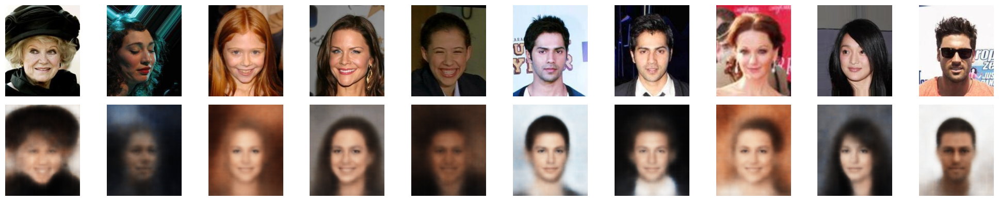

In [ ]:
X, y = next(iter(test_dataloader))
X = X.to(device)
pred, _, _ = model(X)
pred = pred.reshape(X.shape[0],3,218,178)
def plot_images(originals, predictions, num_images=10):
    fig, axes = plt.subplots(2, num_images, figsize=(2 * num_images, 4))
    for i in range(num_images):
        axes[0, i].imshow(originals[i].permute(1, 2, 0).cpu().squeeze())
        axes[0, i].axis("off")
        axes[1, i].imshow(predictions[i].permute(1, 2, 0).detach().cpu().squeeze())
        axes[1, i].axis("off")
    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Reconstruit")
    plt.tight_layout()
    plt.show()

plot_images(X, pred, num_images=10)

Les résultats sont bien meilleurs que pour le VAE linéaire, on reconnait bien des visages et ,certains éléments commencent à ressortir (chapeau de la 1ere image, les cheveux roux, la couleurs du fond). Cependant ce n'est pas parfait car de nombreux compromis sont fait mais c'est encourageant.

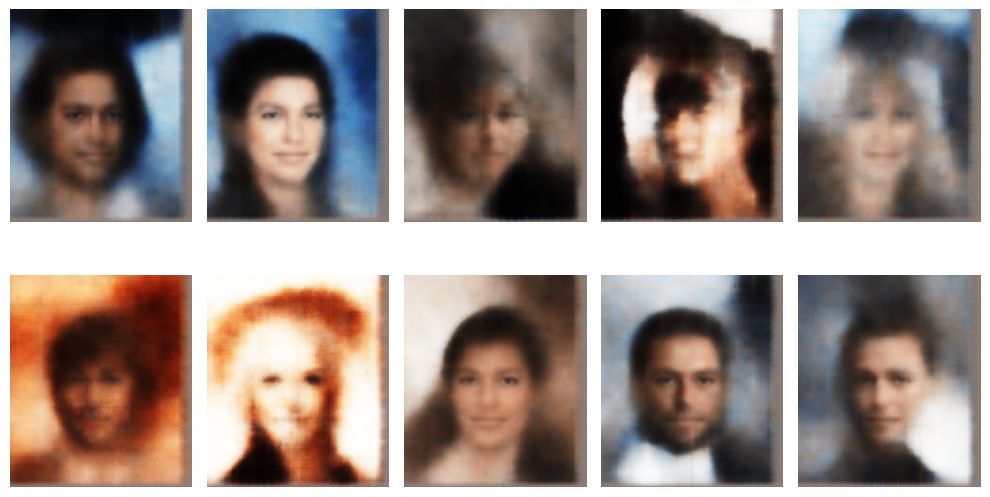

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

latent_dim = 20
fig, axes = plt.subplots(2, 5, figsize=(10, 6))
axes = axes.flatten()

for i in range(10):
    # Génère mu et logvar aléatoirement
    mean = torch.randn(1, latent_dim).to(device)
    log_var = torch.randn(1, latent_dim).to(device)

    # Reparameterize
    with torch.no_grad():
        z = model.reparameterize(mean, log_var)
        y = model.decode(z)

    # Format image
    image = y.cpu().squeeze().numpy()
    image = np.transpose(image, (1, 2, 0))  # (H, W, C)

    axes[i].imshow(image, cmap="gray")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Le CNN permet de générer des visages plus humains et un fond contrairement au NN linéaire.

***

# PARTIE III features

In [ ]:
features.shape

(40,)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Déclaration du modèle CNN pour l'autoencodeur variationnel (VAE) avec des caractéristiques supplémentaires
class CNN(nn.Module):

    def __init__(self, latent_dim=20, feature_dim=40):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.Conv2d(32, 64,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.Conv2d(64, 128,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.Conv2d(128, 256,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.Conv2d(256,512,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU()
        )

        input_shape = (3, 218, 178)
        _, h, w = input_shape
        for _ in range(5):
            h = (h + 2*1 - 1*(3 - 1) - 1)//2 + 1
            w = (w + 2*1 - 1*(3 - 1) - 1)//2 + 1
        self.h = h
        self.w = w

        self.flatten_dim = 512 * h * w

        self.fc_mu = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_dim, latent_dim)

        self.fc_dec = nn.Linear(latent_dim + feature_dim, self.flatten_dim)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 256, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(256, 128,kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(128, 64,kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.Sigmoid()
        )

    def encode(self, x):
        y = self.encoder(x)
        y = y.view(y.size(0), -1)
        mu = self.fc_mu(y)
        logvar = self.fc_logvar(y)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z,feature):
        z = torch.cat([z, feature], dim=1)
        h = self.fc_dec(z)
        h = h.view(h.size(0), 512, self.h, self.w)
        out = self.decoder(h)
        return out

    def forward(self, x, feature):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z,feature)
        x_hat = x_hat[:, :, :x.size(2), :x.size(3)]

        return x_hat, mu, logvar

model = CNN().to(device)
print(model)


CNN(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.01)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.01)
    (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track

## Entraînement du VAE Conditionnel

### Modifications par rapport au VAE standard
- Intégration des attributs dans le processus d'entraînement
- Modification de la fonction de perte pour tenir compte des attributs
- Ajustement des fonctions d'entraînement et de test

### Processus d'entraînement
1. Passage des images ET des attributs au modèle
2. Génération des reconstructions conditionnées
3. Optimisation des pertes combinées

In [ ]:
# Toujours la même perte et le même optimiseur
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X = X.to(device)
        y=y.to(device)
        # Compute prediction error
        pred,mu,log_sigma = model(X,y)
        reconstruction_loss = torch.sum((pred -  X).pow(2))
        kl = torch.sum(mu.pow(2) + log_sigma.exp() -1 - log_sigma)
        loss = reconstruction_loss + kl

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

In [ ]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            y=y.to(device)
            pred,_,_ = model(X,y)
            test_loss += loss_fn(pred, X).item()
    test_loss /= num_batches
    correct /= size
    print(f"Test loss: {test_loss:>8f} \n")

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

print("Done!")

Epoch 1
-------------------------------
loss: 7133716.000000  [  512/162770]
loss: 3043153.750000  [51712/162770]
loss: 2011334.625000  [102912/162770]
loss: 1672326.375000  [154112/162770]
Test loss: 0.026258 

Epoch 2
-------------------------------
loss: 1655445.875000  [  512/162770]
loss: 1477416.750000  [51712/162770]
loss: 1392887.500000  [102912/162770]
loss: 1335304.125000  [154112/162770]
Test loss: 0.021437 

Epoch 3
-------------------------------
loss: 1357431.250000  [  512/162770]
loss: 1284094.250000  [51712/162770]
loss: 1264827.000000  [102912/162770]
loss: 1238590.875000  [154112/162770]
Test loss: 0.020005 

Epoch 4
-------------------------------
loss: 1268053.375000  [  512/162770]
loss: 1186908.375000  [51712/162770]
loss: 1191614.250000  [102912/162770]
loss: 1155682.000000  [154112/162770]
Test loss: 0.018767 

Epoch 5
-------------------------------
loss: 1193343.625000  [  512/162770]
loss: 1136898.875000  [51712/162770]
loss: 1150500.750000  [102912/162770]


## Validation du modèle conditionnel

### Tests de reconstruction
Nous vérifions que le modèle peut :
1. Reconstruire fidèlement les images d'origine
2. Respecter les attributs spécifiés
3. Maintenir la qualité visuelle des visages

Les images de la première ligne sont les originaux, celles de la deuxième ligne sont les reconstructions avec les mêmes attributs.

In [ ]:
import time
timestamp = time.strftime("%Y%m%d-%H%M%S")
filename = f"CNN_features_model_{timestamp}.pth"
torch.save(model.state_dict(), filename)

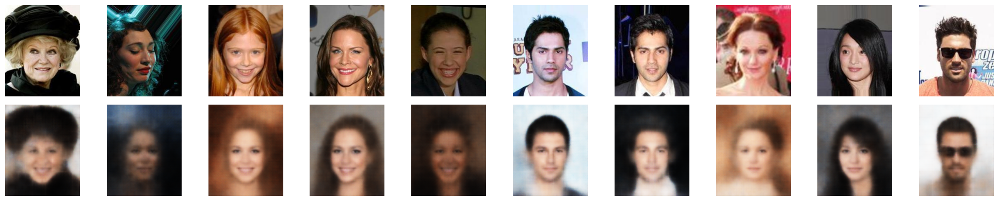

In [ ]:
X, y = next(iter(test_dataloader))
X = X.to(device)
y=y.to(device)
pred, _, _ = model(X,y)
pred = pred.reshape(X.shape[0],3,218,178)
def plot_images(originals, predictions, num_images=10):
    fig, axes = plt.subplots(2, num_images, figsize=(2 * num_images, 4))
    for i in range(num_images):
        axes[0, i].imshow(originals[i].permute(1, 2, 0).cpu().squeeze())
        axes[0, i].axis("off")
        axes[1, i].imshow(predictions[i].permute(1, 2, 0).detach().cpu().squeeze())
        axes[1, i].axis("off")
    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Reconstruit")
    plt.tight_layout()
    plt.show()

plot_images(X, pred, num_images=10)

les accessoires sont bien mieux générés, les lunettes de soleil de la dernière image n'était pas reproduite dans le CNN sans features, maintenant si.

In [ ]:
features

array(['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive',
       'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose',
       'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair',
       'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee',
       'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male',
       'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard',
       'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline',
       'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair',
       'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick',
       'Wearing_Necklace', 'Wearing_Necktie', 'Young'], dtype='<U19')

## Génération avec attributs spécifiques

### Test avec l'attribut 'lunettes'
Dans cette expérience, nous allons :
1. Générer des points aléatoires dans l'espace latent
2. Activer spécifiquement l'attribut 'lunettes' (indice 15)
3. Générer 10 visages différents portant des lunettes

Cela permet de vérifier que le modèle a bien appris à conditionner la génération avec les attributs.

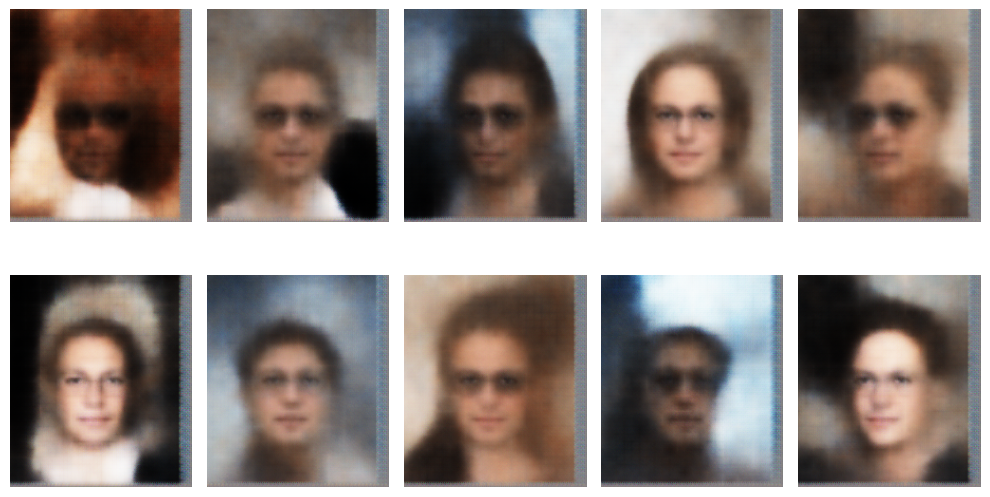

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

latent_dim = 20  # Assure-toi que c'est le même que dans ton modèle
fig, axes = plt.subplots(2, 5, figsize=(10, 6))
axes = axes.flatten()

for i in range(10):
    # Génère mu et logvar aléatoirement
    mean = torch.randn(1, latent_dim).to(device)
    log_var = torch.randn(1, latent_dim).to(device)
    feature=[-1]*40
    feature[15]=1
    feature = torch.tensor(feature, dtype=torch.float32).unsqueeze(0).to(device)
    # Reparameterize
    with torch.no_grad():
        z = model.reparameterize(mean, log_var)
        y = model.decode(z,feature)

    # Format image
    image = y.cpu().squeeze().numpy()
    image = np.transpose(image, (1, 2, 0))  # (H, W, C)

    axes[i].imshow(image, cmap="gray")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


On voit que les visages formés ont des lunettes même si elles sont peu visibles, notamment sur la dernière photo. Il y a des lunettes de vue et de soleil

## Génération avec combinaisons d'attributs aléatoires

### Expérimentation avec attributs multiples
Nous testons ici la capacité du modèle à :
1. Gérer plusieurs attributs simultanément
2. Produire des visages cohérents avec des combinaisons aléatoires
3. Maintenir la qualité visuelle avec des contraintes multiples

Pour chaque image, nous sélectionnons aléatoirement 3 attributs parmi les 40 disponibles.

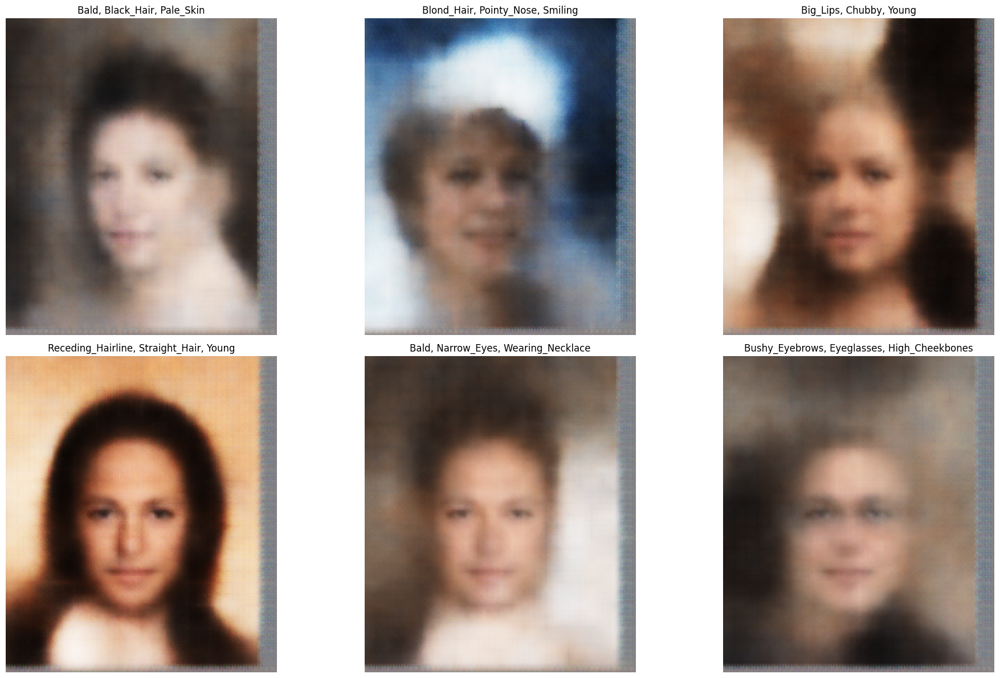

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np
import random

latent_dim = 20
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i in range(6):
    # Génère mu et logvar aléatoirement
    mean = torch.randn(1, latent_dim).to(device)
    log_var = torch.randn(1, latent_dim).to(device)
    feature=[-1]*40
    indices = [j for j in range(40)]
    random_indices = random.sample(indices, 3)
    for idx in random_indices:
        feature[idx] = 1
    feature = torch.tensor(feature, dtype=torch.float32).unsqueeze(0).to(device)
    # Reparameterize
    with torch.no_grad():
        z = model.reparameterize(mean, log_var)
        y = model.decode(z,feature)

    # Format image
    image = y.cpu().squeeze().numpy()
    image = np.transpose(image, (1, 2, 0))  # (H, W, C)

    axes[i].imshow(image, cmap="gray")
    attr=feature == 1
    axes[i].set_title(", ".join(features[attr[0].cpu().numpy()]))
    axes[i].axis("off")

plt.tight_layout()
plt.show()


# Conclusion

## Résultats obtenus

1. **Partie 1** : VAE basique
   - Reconstruction correcte des visages
   - Espace latent structuré en dimension 2

2. **Partie 2** : Amélioration CNN
   - Meilleure qualité de reconstruction
   - Préservation des détails fins

3. **Partie 3** : Conditionnement
   - Contrôle réussi des attributs
   - Génération cohérente avec attributs multiples

Les résultats restent flous mais sont cohérents et on obtient des visages avec les bons attributs.

In [ ]:
attr[0]

tensor([False, False, False, False, False, False, False, False, False,  True,
        False, False, False, False, False,  True, False, False,  True, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False,  True, False, False, False, False, False, False, False])

In [ ]:
# Importation du modèle sauvegardé
model = CNN()  # recrée l'architecture
# Load the state dictionary, mapping CUDA tensors to CPU
model.load_state_dict(torch.load("/content/CNN_features_model_20250527-184931.pth", map_location=torch.device('cpu')))
model.eval()
model=model.to(device) # Move the model to the currently available device (CPU)
print(model)

CNN(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.01)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.01)
    (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track

***

## Essai d'une reconstruction avec une photo de Romain

In [ ]:
features

array(['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive',
       'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose',
       'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair',
       'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee',
       'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male',
       'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard',
       'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline',
       'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair',
       'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick',
       'Wearing_Necklace', 'Wearing_Necktie', 'Young'], dtype='<U19')

Saving 1702842431689.jpeg to 1702842431689 (1).jpeg


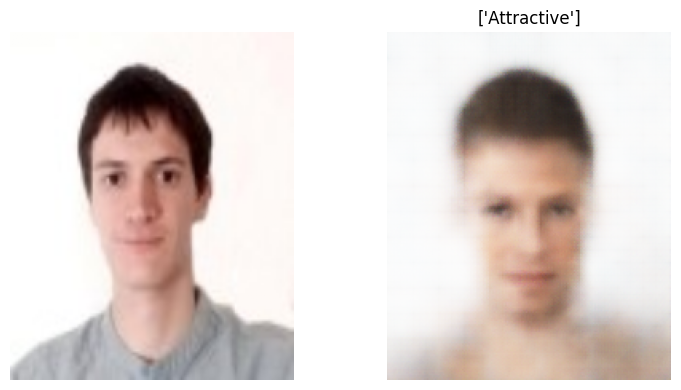

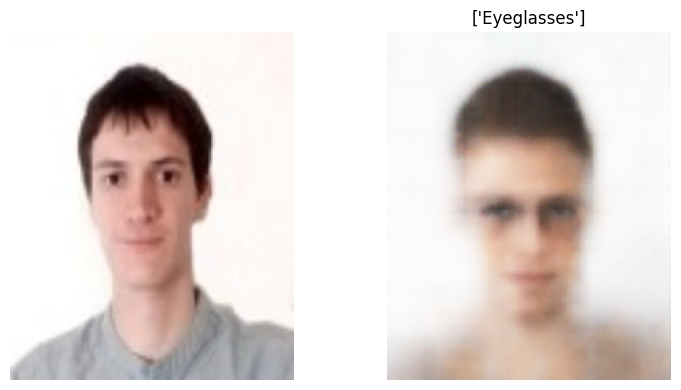

In [ ]:
from google.colab import files
from PIL import Image
import io
import torchvision.transforms as T

# Upload the file
uploaded = files.upload()

if uploaded:

  for i in (2, 15):
      filename = list(uploaded.keys())[0]
      img_bytes = uploaded[filename]


      transform = T.Compose([
          T.Resize((218, 178)),
          T.ToTensor(),
      ])

      img_tensor = transform(image).unsqueeze(0).to(device)

      feature = [-1] * 40
      feature[i] = 1
      feature_tensor = torch.tensor(feature, dtype=torch.float32).unsqueeze(0).to(device)


      with torch.no_grad():
          pred, _, _ = model(img_tensor, feature_tensor)

      pred = pred.reshape(1, 3, 218, 178)

      fig, axes = plt.subplots(1, 2, figsize=(8, 4))

      axes[0].imshow(img_tensor.squeeze().permute(1, 2, 0).cpu().squeeze())
      axes[0].axis("off")

      axes[1].imshow(pred.squeeze().permute(1, 2, 0).detach().cpu().squeeze())
      axes[1].axis("off")
      axes[1].set_title(features[np.array(feature)==1])

      plt.tight_layout()
      plt.show()


else:
    print("No file was uploaded.")

Des lunettes de soleil ont bien été insérées, même si elles ne sont pas trop visibles (je suis aussi devenu plus attractif).

***

# Amélioration du modèle

Dans cette partie, on a cherché à améliorer le modèle utilisé pour la génération et la reconstruction. Comme premier changement, on utilise un espace latent en 128 dimensions au lieu de 20, comme dans l'exemple. On augmente aussi à 15 époques la durée d'apprentissage au lieu de 10.

Comme on a beaucoup de données, on pense qu'il n'y aura pas de problème de surapprentissage même avec 128 dimensions.

On espère avec ce modèle être plus précis dans la reconstruction et la génération aléatoire.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNN3(nn.Module):

    def __init__(self, latent_dim=128, feature_dim=40):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.Conv2d(32, 64,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.Conv2d(64, 128,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.Conv2d(128, 256,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.Conv2d(256,512,kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU()
        )

        input_shape = (3, 218, 178)
        _, h, w = input_shape
        for _ in range(5):
            h = (h + 2*1 - 1*(3 - 1) - 1)//2 + 1
            w = (w + 2*1 - 1*(3 - 1) - 1)//2 + 1
        self.h = h
        self.w = w

        self.flatten_dim = 512 * h * w

        self.fc_mu = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_dim, latent_dim)

        self.fc_dec = nn.Linear(latent_dim + feature_dim, self.flatten_dim)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 256, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(256, 128,kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(128, 64,kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=3,stride=2,padding=1,output_padding=1),
            nn.Sigmoid()
        )

    def encode(self, x):
        y = self.encoder(x)
        y = y.view(y.size(0), -1)  # important
        mu = self.fc_mu(y)
        logvar = self.fc_logvar(y)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z,feature):
        z = torch.cat([z, feature], dim=1)
        h = self.fc_dec(z)
        h = h.view(h.size(0), 512, self.h, self.w)
        out = self.decoder(h)
        return out

    def forward(self, x, feature):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z,feature)
        x_hat = x_hat[:, :, :x.size(2), :x.size(3)]

        return x_hat, mu, logvar

model = CNN3().to(device)
print(model)


CNN3(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.01)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.01)
    (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, trac

In [ ]:
epochs = 15
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

print("Done!")

Epoch 1
-------------------------------
loss: 7085057.000000  [  512/162770]
loss: 2842821.000000  [51712/162770]
loss: 1943752.500000  [102912/162770]
loss: 1544477.625000  [154112/162770]
Test loss: 0.022318 

Epoch 2
-------------------------------
loss: 1511595.250000  [  512/162770]
loss: 1276139.750000  [51712/162770]
loss: 1178795.875000  [102912/162770]
loss: 1097302.250000  [154112/162770]
Test loss: 0.015603 

Epoch 3
-------------------------------
loss: 1110769.500000  [  512/162770]
loss: 1041618.250000  [51712/162770]
loss: 1025425.250000  [102912/162770]
loss: 981978.500000  [154112/162770]
Test loss: 0.013814 

Epoch 4
-------------------------------
loss: 999355.375000  [  512/162770]
loss: 955438.750000  [51712/162770]
loss: 960729.875000  [102912/162770]
loss: 929883.750000  [154112/162770]
Test loss: 0.012967 

Epoch 5
-------------------------------
loss: 947045.250000  [  512/162770]
loss: 913158.437500  [51712/162770]
loss: 923896.000000  [102912/162770]
loss: 89

In [ ]:
import time
timestamp = time.strftime("%Y%m%d-%H%M%S")
filename = f"CNN_features_128_model_{timestamp}.pth"
torch.save(model.state_dict(), filename)

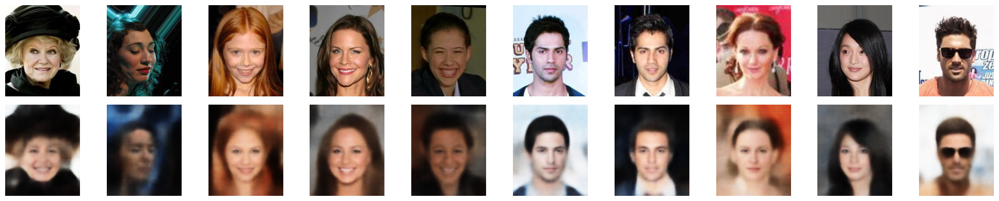

In [ ]:
X, y = next(iter(test_dataloader))
X = X.to(device)
y=y.to(device)
pred, _, _ = model(X,y)
pred = pred.reshape(X.shape[0],3,218,178)
def plot_images(originals, predictions, num_images=10):
    fig, axes = plt.subplots(2, num_images, figsize=(2 * num_images, 4))
    for i in range(num_images):
        axes[0, i].imshow(originals[i].permute(1, 2, 0).cpu().squeeze())
        axes[0, i].axis("off")
        axes[1, i].imshow(predictions[i].permute(1, 2, 0).detach().cpu().squeeze())
        axes[1, i].axis("off")
    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Reconstruit")
    plt.tight_layout()
    plt.show()

plot_images(X, pred, num_images=10)

Le modèle donne des résultats plus précis, comparé au modèle précédent, le fond est mieux reconstruit et le visage également. Les photos sont moins floues.

***

## Génération aléatoire

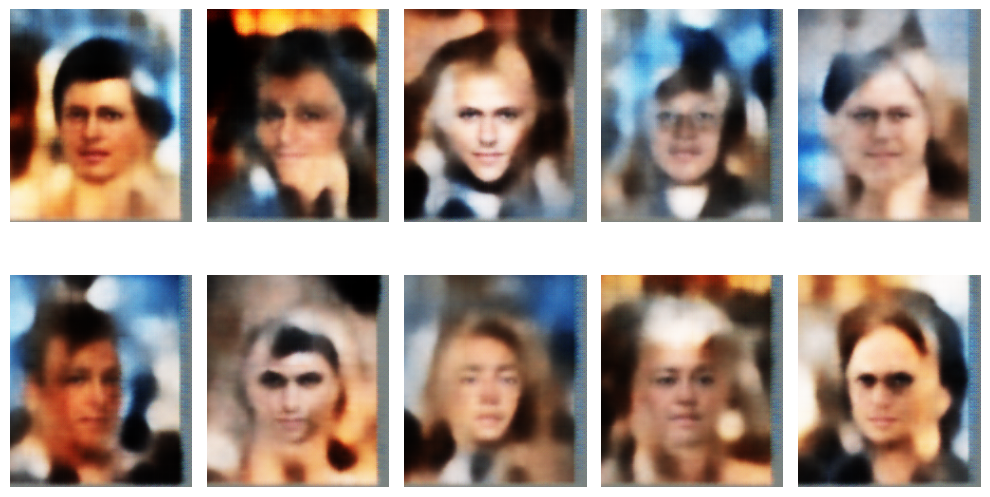

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

latent_dim = 128
fig, axes = plt.subplots(2, 5, figsize=(10, 6))
axes = axes.flatten()

for i in range(10):
    # Génère mu et logvar aléatoirement
    mean = torch.randn(1, latent_dim).to(device)
    log_var = torch.randn(1, latent_dim).to(device)
    feature=[-1]*40
    feature[15]=1
    feature = torch.tensor(feature, dtype=torch.float32).unsqueeze(0).to(device)
    # Reparameterize
    with torch.no_grad():
        z = model.reparameterize(mean, log_var)
        y = model.decode(z,feature)

    # Format image
    image = y.cpu().squeeze().numpy()
    image = np.transpose(image, (1, 2, 0))  # (H, W, C)

    axes[i].imshow(image, cmap="gray")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


Le nouveau modèle reconstruit des visages. Le problème qu'on voit est qu'il y a une inconsistance entre le visage et le fond. Cependant les viasages sont bien fait, mais le contour est devenu chaotique.

In [ ]:
model = CNN3(latent_dim=128)# recrée l'architecture
# Load the state dictionary, mapping CUDA tensors to CPU
model.load_state_dict(torch.load("/content/CNN_features_128_model_20250528-171132.pth", map_location=torch.device('cpu')))
model.eval()
model=model.to(device) # Move the model to the currently available device (CPU)
print(model)

CNN3(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.01)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.01)
    (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, trac

***

## Essai avec une image personnelle

On reprend la même photo de Romain et on reconstruit l'image.

Saving 1702842431689.jpeg to 1702842431689 (2).jpeg


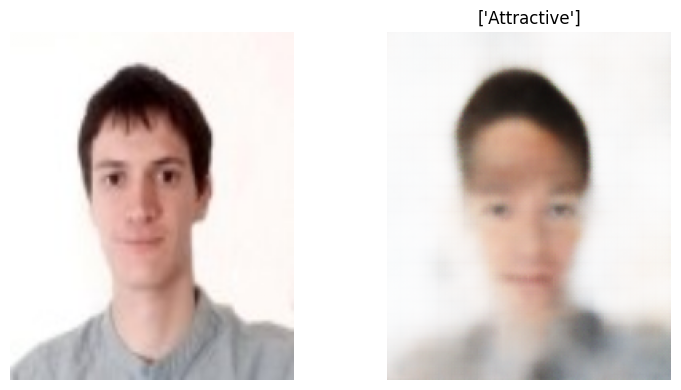

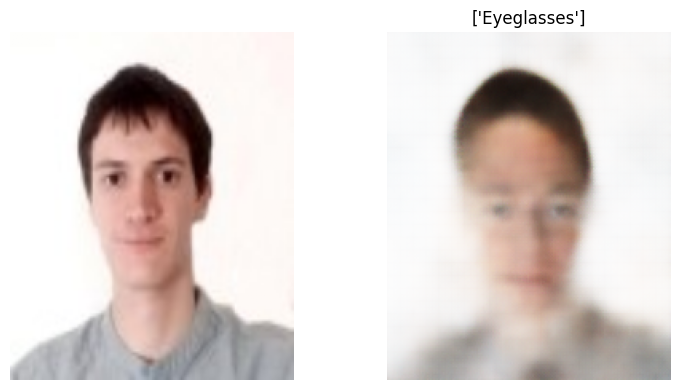

In [ ]:
from google.colab import files
from PIL import Image
import io
import torchvision.transforms as T

# Upload the file
uploaded = files.upload()

if uploaded:

  for i in (2, 15):
      filename = list(uploaded.keys())[0]
      img_bytes = uploaded[filename]


      transform = T.Compose([
          T.Resize((218, 178)),
          T.ToTensor(),
      ])

      img_tensor = transform(image).unsqueeze(0).to(device)

      feature = [-1] * 40
      feature[i] = 1
      feature_tensor = torch.tensor(feature, dtype=torch.float32).unsqueeze(0).to(device)


      with torch.no_grad():
          pred, _, _ = model(img_tensor, feature_tensor)

      pred = pred.reshape(1, 3, 218, 178)

      fig, axes = plt.subplots(1, 2, figsize=(8, 4))

      axes[0].imshow(img_tensor.squeeze().permute(1, 2, 0).cpu().squeeze())
      axes[0].axis("off")

      axes[1].imshow(pred.squeeze().permute(1, 2, 0).detach().cpu().squeeze())
      axes[1].axis("off")
      axes[1].set_title(features[np.array(feature)==1])

      plt.tight_layout()
      plt.show()


else:
    print("No file was uploaded.")

Le résultat est décevant, les lunettes sont peu visibles et le visage est déformé. Au vu du résultat avec les images du batch test on peut penser qu'il y a eu du surapprentissage.